# B3 — Histogram dan Perbaikan Citra

Evaluasi Praktikum P1–P4 Computer Vision
SIMUTEH — Klasifikasi Kualitas Daun Teh

# 3.1 Lembar Hitung Manual

A. HISTOGRAM
Intensitas 0: 0 piksel
Intensitas 1: 2 piksel
Intensitas 2: 7 piksel
Intensitas 3: 6 piksel
Intensitas 4: 1 piksel
Intensitas 5: 0 piksel
Intensitas 6: 0 piksel
Intensitas 7: 0 piksel


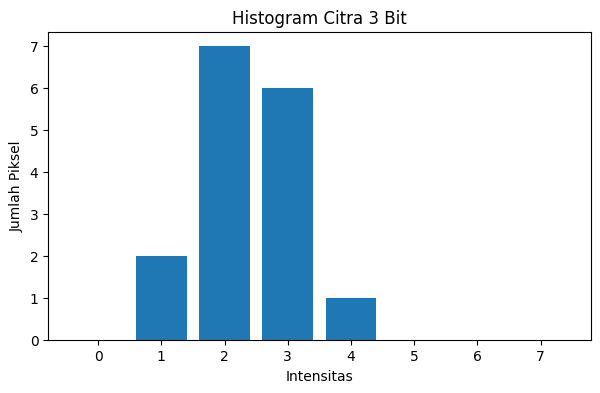


B. PEREGANGAN KONTRAS
Matriks hasil:
[[0 2 2 5]
 [2 2 5 5]
 [0 2 5 7]
 [2 5 5 2]]

C. EKUALISASI HISTOGRAM
 r | n | PDF | CDF | 7 x CDF | s
 0 |  0 | 0.0000 | 0.0000 | 0.0000 | 0
 1 |  2 | 0.1250 | 0.1250 | 0.8750 | 1
 2 |  7 | 0.4375 | 0.5625 | 3.9375 | 4
 3 |  6 | 0.3750 | 0.9375 | 6.5625 | 7
 4 |  1 | 0.0625 | 1.0000 | 7.0000 | 7
 5 |  0 | 0.0000 | 1.0000 | 7.0000 | 7
 6 |  0 | 0.0000 | 1.0000 | 7.0000 | 7
 7 |  0 | 0.0000 | 1.0000 | 7.0000 | 7

Matriks hasil ekualisasi:
[[1 4 4 7]
 [4 4 7 7]
 [1 4 7 7]
 [4 7 7 4]]

D. OPERASI TITIK
Negatif r=60: 195
Kontras r=120: 138
Kontras r=210: 255
Gamma 0.6, r=100: 145.42
Gamma 1.8, r=100: 47.29


In [35]:

import numpy as np
import matplotlib.pyplot as plt

# Matriks citra 3 bit (L = 8)
M = np.array([
    [1, 2, 2, 3],
    [2, 2, 3, 3],
    [1, 2, 3, 4],
    [2, 3, 3, 2]
])

# A. Histogram
hist = np.bincount(M.flatten(), minlength=8)

print("A. HISTOGRAM")
for r, n in enumerate(hist):
    print(f"Intensitas {r}: {n} piksel")

plt.figure(figsize=(7, 4))
plt.bar(range(8), hist)
plt.xlabel("Intensitas")
plt.ylabel("Jumlah Piksel")
plt.title("Histogram Citra 3 Bit")
plt.xticks(range(8))
plt.show()


# B. Peregangan Kontras
rmin = M.min()
rmax = M.max()

M_regang = np.rint(
    (M - rmin) / (rmax - rmin) * 7
).astype(int)

print("\nB. PEREGANGAN KONTRAS")
print("Matriks hasil:")
print(M_regang)


# C. Ekualisasi Histogram
pdf = hist / M.size
cdf = np.cumsum(pdf)
skala = 7 * cdf
s = np.rint(skala).astype(int)

print("\nC. EKUALISASI HISTOGRAM")
print(" r | n | PDF | CDF | 7 x CDF | s")
for r in range(8):
    print(
        f"{r:2d} | {hist[r]:2d} | "
        f"{pdf[r]:.4f} | {cdf[r]:.4f} | "
        f"{skala[r]:.4f} | {s[r]}"
    )

M_ekualisasi = s[M]

print("\nMatriks hasil ekualisasi:")
print(M_ekualisasi)


# D. Operasi Titik 8 Bit
print("\nD. OPERASI TITIK")

# Negatif
r = 60
print("Negatif r=60:", 255 - r)

# Kontras
for r in [120, 210]:
    hasil = np.clip(1.4 * r - 30, 0, 255)
    print(f"Kontras r={r}: {hasil:.0f}")

# Koreksi gamma
for gamma in [0.6, 1.8]:
    r = 100
    hasil = 255 * (r / 255) ** gamma
    print(f"Gamma {gamma}, r=100: {hasil:.2f}")


# 3.2 Diagnosis Mutu

teh_041.png {'rerata': 177.4, 'simpangan_baku': 42.4, 'min': 68, 'maks': 222, 'persen_gelap': 0.0, 'persen_terang': 7.4}
teh_042.png {'rerata': 138.6, 'simpangan_baku': 50.3, 'min': 13, 'maks': 193, 'persen_gelap': 16.3, 'persen_terang': 0.0}
teh_043.png {'rerata': 216.7, 'simpangan_baku': 24.0, 'min': 139, 'maks': 254, 'persen_gelap': 0.0, 'persen_terang': 79.9}
teh_044.png {'rerata': 155.3, 'simpangan_baku': 14.8, 'min': 109, 'maks': 187, 'persen_gelap': 0.0, 'persen_terang': 0.0}
teh_045.png {'rerata': 123.1, 'simpangan_baku': 55.5, 'min': 19, 'maks': 249, 'persen_gelap': 3.2, 'persen_terang': 9.4}


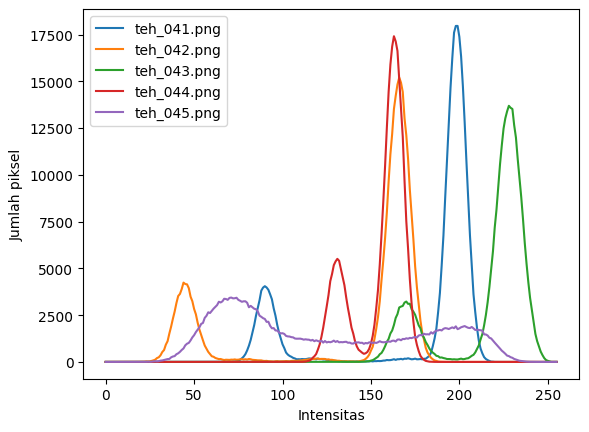

In [39]:
# Statistik dan histogram untuk diagnosis
from utils_cv import statistik

for nama in ["teh_041.png", "teh_042.png", "teh_043.png",
             "teh_044.png", "teh_045.png"]:

    gray = cv2.cvtColor(
        cv2.imread(os.path.join(DATA_DIR, "citra", nama)),
        cv2.COLOR_BGR2GRAY
    )

    print(nama, statistik(gray))

    hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
    plt.plot(hist, label=nama)

plt.xlabel("Intensitas")
plt.ylabel("Jumlah piksel")
plt.legend()
plt.show()

teh_021.png {'rerata': 163.5, 'simpangan_baku': 38.8, 'min': 65, 'maks': 232, 'persen_gelap': 0.0, 'persen_terang': 1.7}
teh_022.png {'rerata': 115.6, 'simpangan_baku': 32.8, 'min': 19, 'maks': 168, 'persen_gelap': 3.4, 'persen_terang': 0.0}
teh_023.png {'rerata': 208.8, 'simpangan_baku': 27.1, 'min': 124, 'maks': 254, 'persen_gelap': 0.0, 'persen_terang': 76.1}
teh_024.png {'rerata': 156.8, 'simpangan_baku': 15.3, 'min': 98, 'maks': 199, 'persen_gelap': 0.0, 'persen_terang': 0.0}
teh_025.png {'rerata': 125.1, 'simpangan_baku': 54.7, 'min': 22, 'maks': 246, 'persen_gelap': 2.0, 'persen_terang': 10.2}


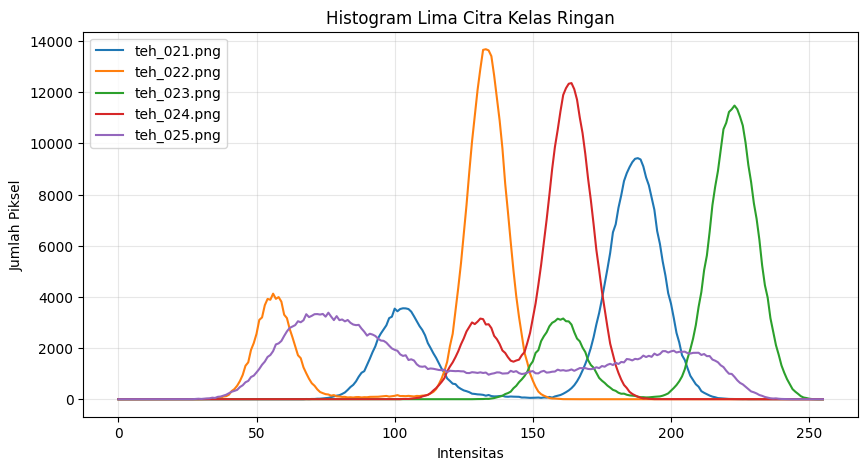

In [40]:
# Statistik dan Histogram Kelas Ringan
daftar_ringan = [
    "teh_021.png", "teh_022.png", "teh_023.png",
    "teh_024.png", "teh_025.png"
]

plt.figure(figsize=(10, 5))

for nama in daftar_ringan:
    img = cv2.imread(os.path.join(DATA_DIR, "citra", nama))
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    print(nama, statistik(gray))

    hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
    plt.plot(hist, label=nama)

plt.title("Histogram Lima Citra Kelas Ringan")
plt.xlabel("Intensitas")
plt.ylabel("Jumlah Piksel")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [41]:
# Tabel 9 - Statistik Citra Lima Kondisi Cahaya

import pandas as pd

data_tabel9 = [
    ["teh_041", "Berat", "Normal", 177.4, 42.4, 68, 222, 0.0, 7.4],
    ["teh_042", "Berat", "Gelap", 138.6, 50.3, 13, 193, 16.3, 0.0],
    ["teh_043", "Berat", "Terang", 216.7, 24.0, 139, 254, 0.0, 79.9],
    ["teh_044", "Berat", "Kontras Rendah", 155.3, 14.8, 109, 187, 0.0, 0.0],
    ["teh_045", "Berat", "Bayangan", 123.1, 55.5, 19, 249, 3.2, 9.4],

    ["teh_021", "Ringan", "Normal", 163.5, 38.8, 65, 232, 0.0, 1.7],
    ["teh_022", "Ringan", "Gelap", 115.6, 32.8, 19, 168, 3.4, 0.0],
    ["teh_023", "Ringan", "Terang", 208.8, 27.1, 124, 254, 0.0, 76.1],
    ["teh_024", "Ringan", "Kontras Rendah", 156.8, 15.3, 98, 199, 0.0, 0.0],
    ["teh_025", "Ringan", "Bayangan", 125.1, 54.7, 22, 246, 2.0, 10.2]
]

kolom = [
    "Citra", "Kelas", "Kondisi Cahaya",
    "Rerata", "Simpangan Baku", "Min", "Maks",
    "Persen Gelap (%)", "Persen Terang (%)"
]

tabel9 = pd.DataFrame(data_tabel9, columns=kolom)

print("TABEL 9. STATISTIK CITRA LIMA KONDISI CAHAYA")
display(tabel9)

# Simpan tabel ke CSV
tabel9.to_csv(
    os.path.join(HASIL_DIR, "b3_tabel9_statistik.csv"),
    index=False
)

TABEL 9. STATISTIK CITRA LIMA KONDISI CAHAYA


,Citra,Kelas,Kondisi Cahaya,Rerata,Simpangan Baku,Min,Maks,Persen Gelap (%),Persen Terang (%)
0,teh_041,Berat,Normal,177.4,42.4,68,222,0.0,7.4
1,teh_042,Berat,Gelap,138.6,50.3,13,193,16.3,0.0
2,teh_043,Berat,Terang,216.7,24.0,139,254,0.0,79.9
3,teh_044,Berat,Kontras Rendah,155.3,14.8,109,187,0.0,0.0
4,teh_045,Berat,Bayangan,123.1,55.5,19,249,3.2,9.4
5,teh_021,Ringan,Normal,163.5,38.8,65,232,0.0,1.7
6,teh_022,Ringan,Gelap,115.6,32.8,19,168,3.4,0.0
7,teh_023,Ringan,Terang,208.8,27.1,124,254,0.0,76.1
8,teh_024,Ringan,Kontras Rendah,156.8,15.3,98,199,0.0,0.0
9,teh_025,Ringan,Bayangan,125.1,54.7,22,246,2.0,10.2


# 3.3 Perbaikan Citra

asli       KB=2.45 sigma=55.5
negatif    KB=2.45 sigma=55.5
cerah+50   KB=2.45 sigma=54.0
kontras    KB=2.46 sigma=78.7
regang     KB=2.56 sigma=80.8
gamma0.5   KB=2.09 sigma=40.2
gamma1.8   KB=3.18 sigma=59.1
ekualisasi KB=1.83 sigma=73.4
CLAHE      KB=2.55 sigma=46.5


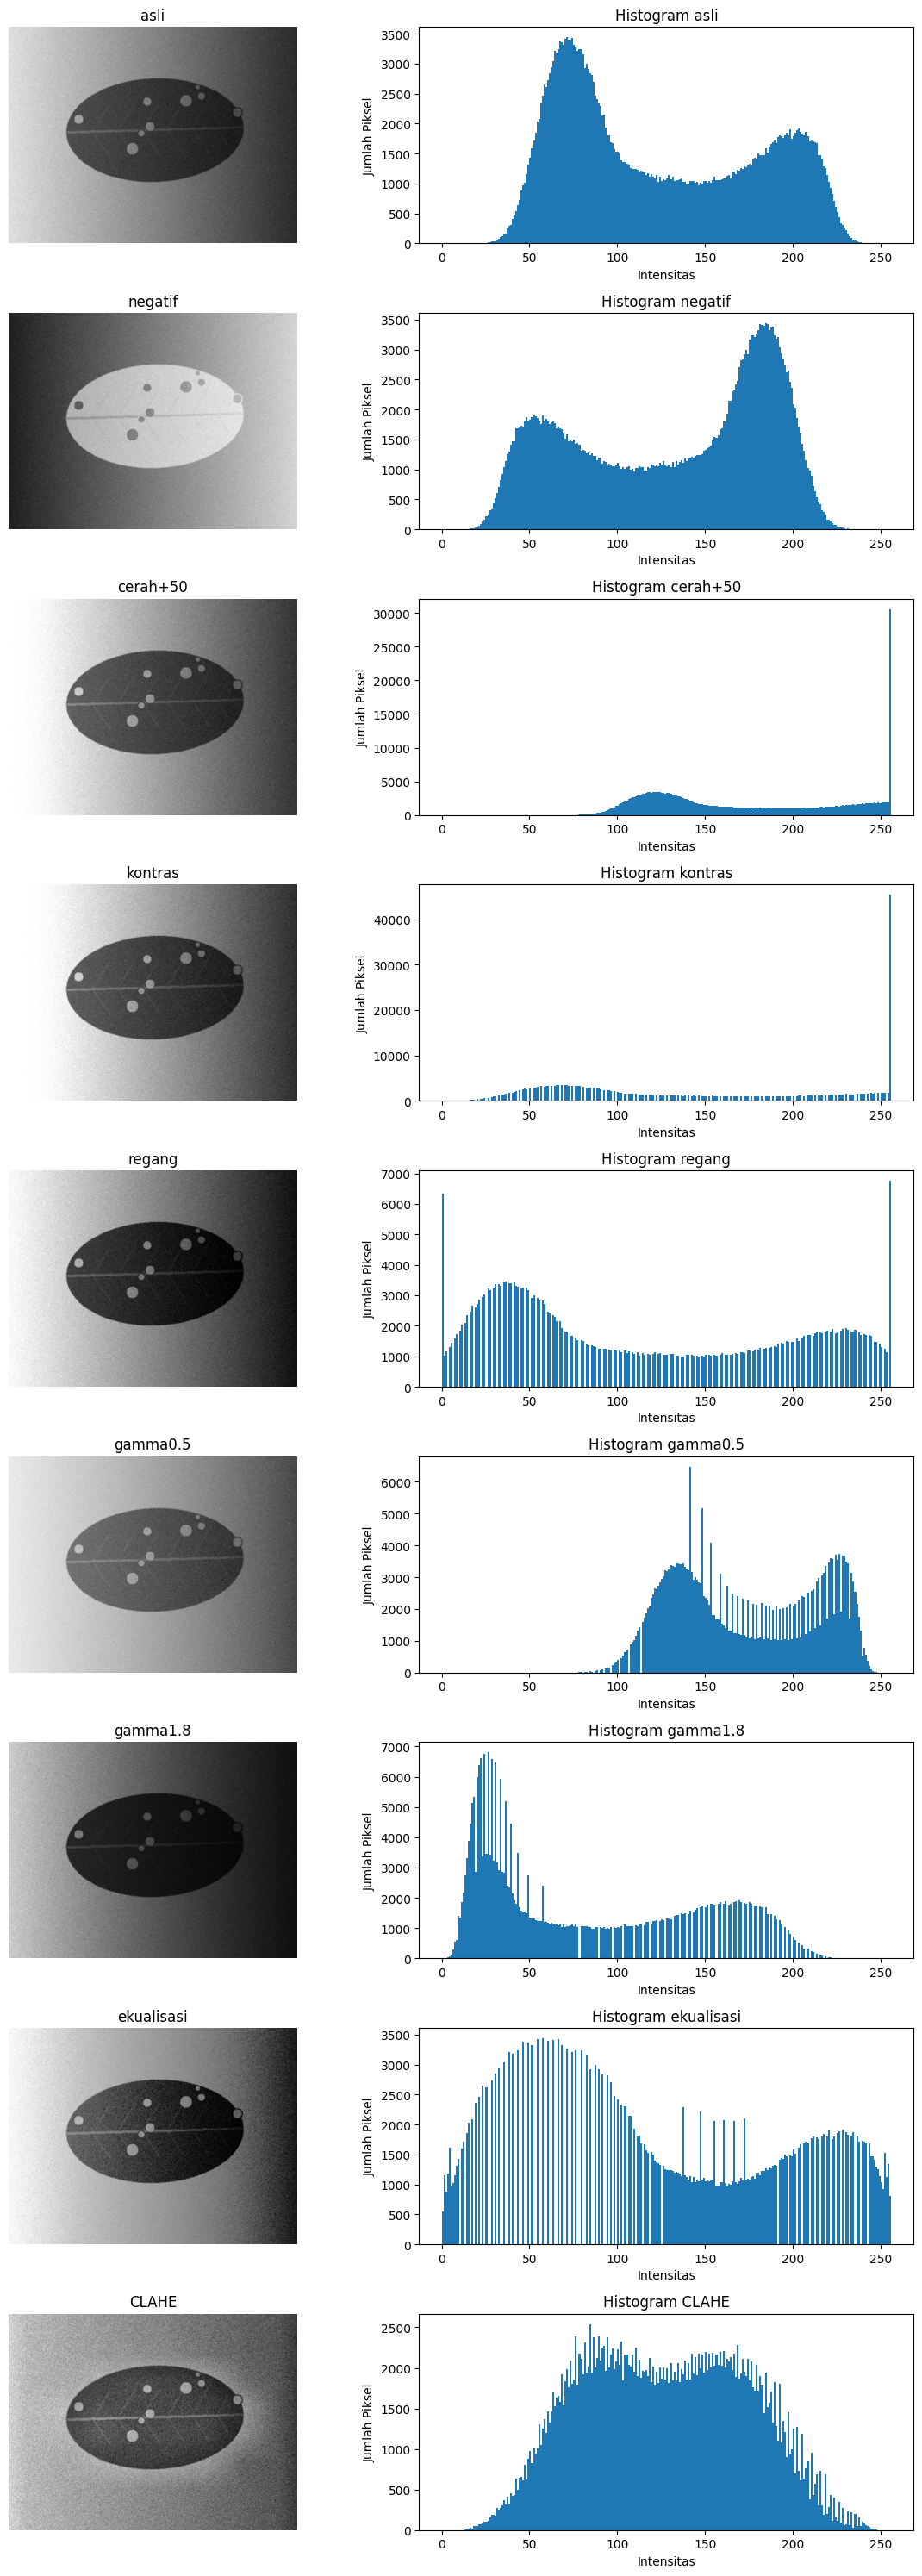

In [42]:
# Perbaikan Citra Kondisi Bayangan
nama = "teh_045.png"

img = cv2.imread(os.path.join(DATA_DIR, "citra", nama))
md = cv2.imread(os.path.join(DATA_DIR, "mask_daun", nama), 0)
mb = cv2.imread(os.path.join(DATA_DIR, "mask_bercak", nama), 0)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Fungsi koreksi gamma
def gamma_lut(g):
    lut = np.array([255 * (i / 255) ** g for i in range(256)])
    return lut.clip(0, 255).astype(np.uint8)

# Peregangan persentil 2 dan 98
rmin, rmax = np.percentile(gray, (2, 98))

# Berbagai metode perbaikan citra
hasil = {
    "asli": gray,
    "negatif": 255 - gray,
    "cerah+50": cv2.add(gray, 50),
    "kontras": cv2.convertScaleAbs(gray, alpha=1.5, beta=-40),
    "regang": np.clip(
        (gray.astype(float) - rmin) / (rmax - rmin) * 255,
        0, 255
    ).astype(np.uint8),
    "gamma0.5": cv2.LUT(gray, gamma_lut(0.5)),
    "gamma1.8": cv2.LUT(gray, gamma_lut(1.8)),
    "ekualisasi": cv2.equalizeHist(gray),
    "CLAHE": cv2.createCLAHE(
        clipLimit=2.0, tileGridSize=(8, 8)
    ).apply(gray)
}

# Menghitung KB dan simpangan baku
for nm, c in hasil.items():
    print(
        f"{nm:10s} KB={kontras_bercak(c, md, mb):.2f} "
        f"sigma={c.std():.1f}"
    )

# Menampilkan citra dan histogram setiap metode
fig, axes = plt.subplots(9, 2, figsize=(12, 30))

for i, (nm, c) in enumerate(hasil.items()):
    axes[i, 0].imshow(c, cmap="gray")
    axes[i, 0].set_title(nm)
    axes[i, 0].axis("off")

    axes[i, 1].hist(c.ravel(), bins=256, range=(0, 256))
    axes[i, 1].set_title(f"Histogram {nm}")
    axes[i, 1].set_xlabel("Intensitas")
    axes[i, 1].set_ylabel("Jumlah Piksel")

plt.tight_layout()
plt.show()

In [43]:
# Tabel Hasil Perbaikan Citra Kondisi Bayangan
import pandas as pd

data_tabel10 = []

for nm, c in hasil.items():
    data_tabel10.append({
        "Metode": nm,
        "Parameter": {
            "asli": "-",
            "negatif": "s = 255 - r",
            "cerah+50": "Beta = +50",
            "kontras": "Alpha = 1.5, Beta = -40",
            "regang": "Persentil 2 dan 98",
            "gamma0.5": "Gamma = 0.5",
            "gamma1.8": "Gamma = 1.8",
            "ekualisasi": "Histogram Equalization",
            "CLAHE": "ClipLimit = 2.0, Tile = 8x8"
        }[nm],
        "KB": round(kontras_bercak(c, md, mb), 2),
        "Simpangan Baku": round(c.std(), 1)
    })

tabel10 = pd.DataFrame(data_tabel10)

print("TABEL 10. HASIL PERBAIKAN CITRA KONDISI BAYANGAN")
display(tabel10)

TABEL 10. HASIL PERBAIKAN CITRA KONDISI BAYANGAN


,Metode,Parameter,KB,Simpangan Baku
0,asli,-,2.45,55.5
1,negatif,s = 255 - r,2.45,55.5
2,cerah+50,Beta = +50,2.45,54.0
3,kontras,"Alpha = 1.5, Beta = -40",2.46,78.7
4,regang,Persentil 2 dan 98,2.56,80.8
5,gamma0.5,Gamma = 0.5,2.09,40.2
6,gamma1.8,Gamma = 1.8,3.18,59.1
7,ekualisasi,Histogram Equalization,1.83,73.4
8,CLAHE,"ClipLimit = 2.0, Tile = 8x8",2.55,46.5


# 3.4 Parameter CLAHE dan Citra Warna

In [44]:
# Eksperimen Parameter CLAHE
nama = "teh_045.png"

img = cv2.imread(os.path.join(DATA_DIR, "citra", nama))
md = cv2.imread(os.path.join(DATA_DIR, "mask_daun", nama), 0)
mb = cv2.imread(os.path.join(DATA_DIR, "mask_bercak", nama), 0)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

hasil_clahe = []

for clip in [1.0, 2.0, 4.0]:
    for tile in [4, 8, 16]:
        clahe = cv2.createCLAHE(
            clipLimit=clip,
            tileGridSize=(tile, tile)
        )

        c = clahe.apply(gray)
        kb = kontras_bercak(c, md, mb)

        hasil_clahe.append([clip, tile, round(kb, 2)])

tabel_clahe = pd.DataFrame(
    hasil_clahe,
    columns=["clipLimit", "tileGridSize", "KB"]
)

print("TABEL EKSPERIMEN PARAMETER CLAHE")
display(tabel_clahe)

tabel_clahe.to_csv(
    os.path.join(HASIL_DIR, "b3_4_eksperimen_clahe.csv"),
    index=False
)

TABEL EKSPERIMEN PARAMETER CLAHE


,clipLimit,tileGridSize,KB
0,1.0,4,3.18
1,1.0,8,2.85
2,1.0,16,2.76
3,2.0,4,2.81
4,2.0,8,2.55
5,2.0,16,2.39
6,4.0,4,2.23
7,4.0,8,2.06
8,4.0,16,1.88


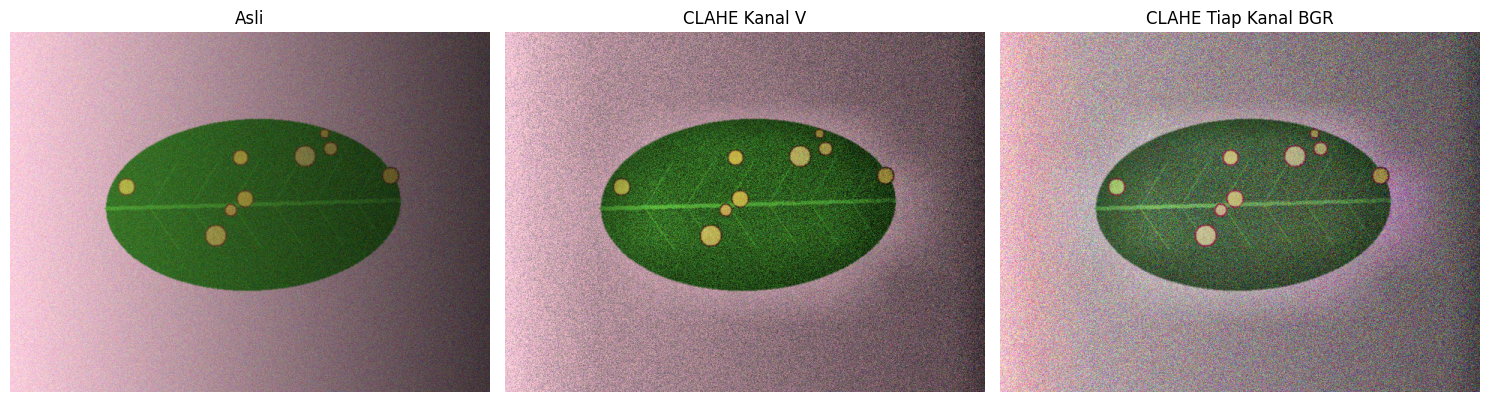

In [45]:
# Perbandingan CLAHE Kanal V dan BGR
nama = "teh_045.png"

img = cv2.imread(os.path.join(DATA_DIR, "citra", nama))
md = cv2.imread(os.path.join(DATA_DIR, "mask_daun", nama), 0)
mb = cv2.imread(os.path.join(DATA_DIR, "mask_bercak", nama), 0)

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

# CLAHE pada kanal V
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
via_v = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

# CLAHE pada setiap kanal BGR
via_bgr = cv2.merge([
    clahe.apply(c) for c in cv2.split(img)
])

# Menampilkan hasil perbandingan
gambar = [img, via_v, via_bgr]
judul = ["Asli", "CLAHE Kanal V", "CLAHE Tiap Kanal BGR"]

plt.figure(figsize=(15, 5))

for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(cv2.cvtColor(gambar[i], cv2.COLOR_BGR2RGB))
    plt.title(judul[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

# 3.5 Perbaikan Citra Pada Empat Kondisi Cahaya


Gelap
Metode terpilih: Gamma 1.8
KB tertinggi: 7.13
teh_042.png | KB sebelum: 5.19 | KB sesudah: 7.13


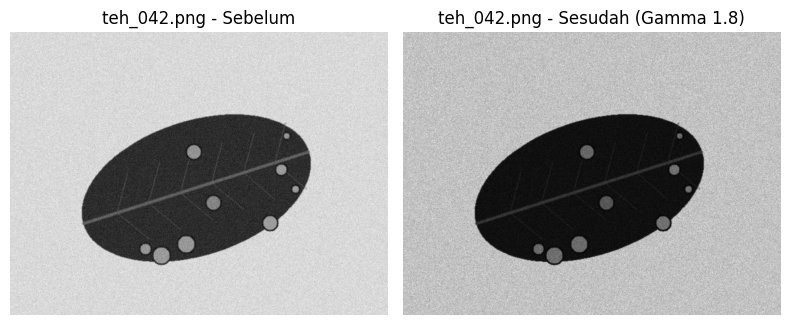

teh_022.png | KB sebelum: 2.00 | KB sesudah: 2.64


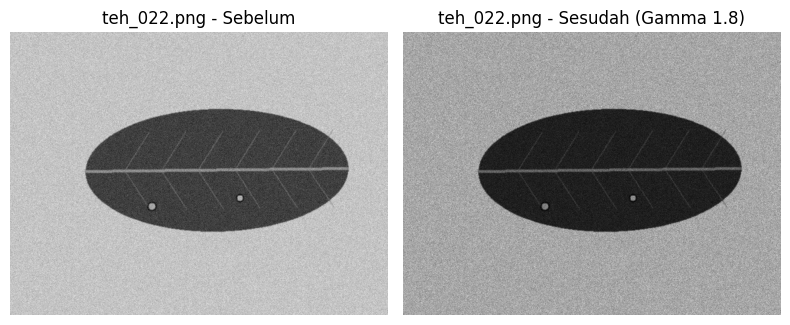


Terang
Metode terpilih: Gamma 1.8
KB tertinggi: 3.39
teh_043.png | KB sebelum: 3.13 | KB sesudah: 3.39


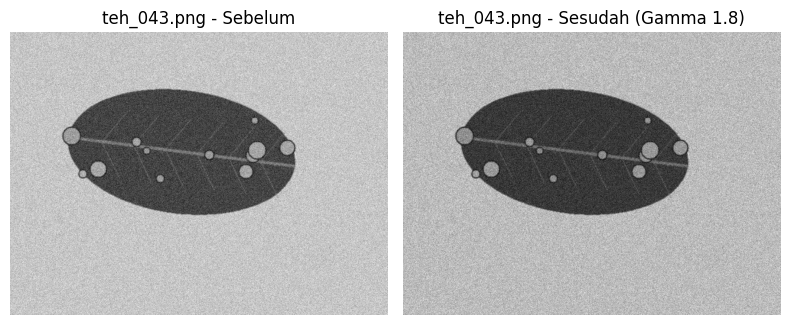

teh_023.png | KB sebelum: 2.88 | KB sesudah: 3.16


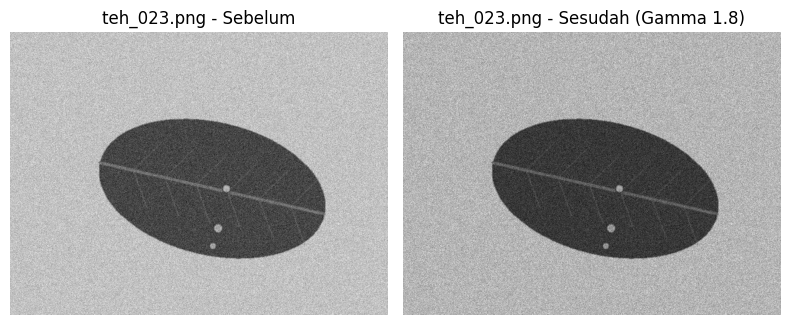


Kontras Rendah
Metode terpilih: Regang
KB tertinggi: 2.71
teh_044.png | KB sebelum: 2.52 | KB sesudah: 2.71


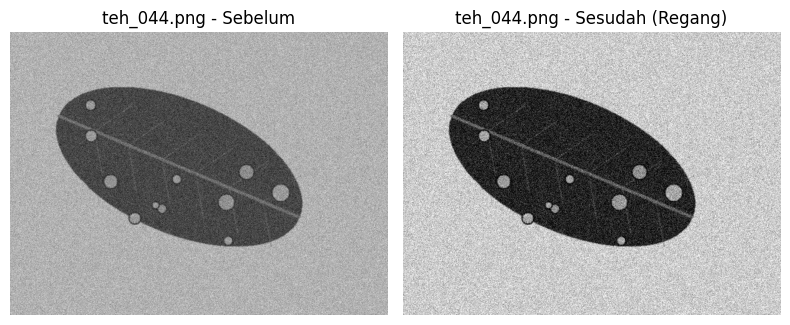

teh_024.png | KB sebelum: 1.10 | KB sesudah: 1.22


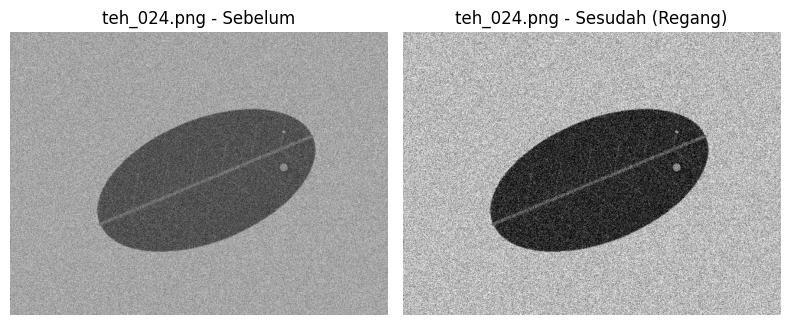


Bayangan
Metode terpilih: Gamma 1.8
KB tertinggi: 3.18
teh_045.png | KB sebelum: 2.45 | KB sesudah: 3.18


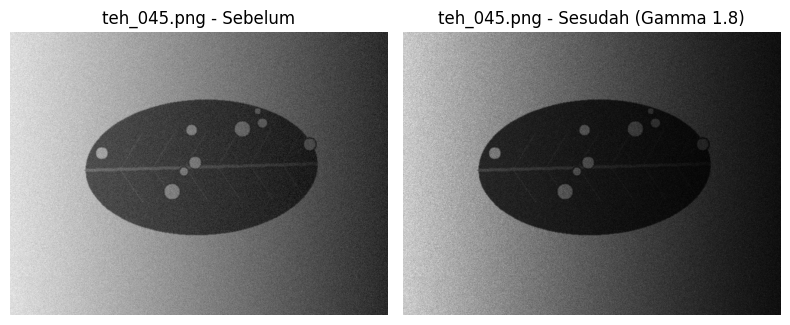

teh_025.png | KB sebelum: 0.19 | KB sesudah: 0.16


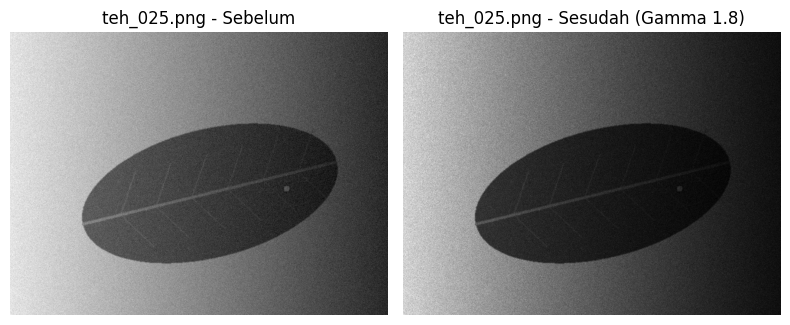

In [46]:
# Perbaikan Citra pada Empat Kondisi Cahaya
pasangan = {
    "Gelap": ["teh_042.png", "teh_022.png"],
    "Terang": ["teh_043.png", "teh_023.png"],
    "Kontras Rendah": ["teh_044.png", "teh_024.png"],
    "Bayangan": ["teh_045.png", "teh_025.png"]
}

def gamma_lut(g):
    lut = np.array([255 * (i / 255) ** g for i in range(256)])
    return lut.clip(0, 255).astype(np.uint8)

def metode_perbaikan(gray):
    rmin, rmax = np.percentile(gray, (2, 98))

    hasil = {
        "Cerah +50": cv2.add(gray, 50),
        "Kontras": cv2.convertScaleAbs(gray, alpha=1.5, beta=-40),
        "Regang": np.clip(
            (gray.astype(float) - rmin) /
            max(rmax - rmin, 1) * 255, 0, 255
        ).astype(np.uint8),
        "Gamma 0.5": cv2.LUT(gray, gamma_lut(0.5)),
        "Gamma 1.8": cv2.LUT(gray, gamma_lut(1.8)),
        "Ekualisasi": cv2.equalizeHist(gray),
        "CLAHE": cv2.createCLAHE(
            clipLimit=1.0,
            tileGridSize=(4, 4)
        ).apply(gray)
    }

    return hasil

hasil_akhir = {}

for kondisi, daftar_citra in pasangan.items():

    # Memilih metode berdasarkan citra kelas berat
    nama_berat = daftar_citra[0]

    img_berat = cv2.imread(
        os.path.join(DATA_DIR, "citra", nama_berat)
    )
    md_berat = cv2.imread(
        os.path.join(DATA_DIR, "mask_daun", nama_berat), 0
    )
    mb_berat = cv2.imread(
        os.path.join(DATA_DIR, "mask_bercak", nama_berat), 0
    )

    gray_berat = cv2.cvtColor(img_berat, cv2.COLOR_BGR2GRAY)
    kandidat = metode_perbaikan(gray_berat)

    nilai_kb = {
        nama: kontras_bercak(citra, md_berat, mb_berat)
        for nama, citra in kandidat.items()
    }

    metode_terpilih = max(nilai_kb, key=nilai_kb.get)

    print(f"\n{kondisi}")
    print("Metode terpilih:", metode_terpilih)
    print("KB tertinggi:", round(nilai_kb[metode_terpilih], 2))

    # Terapkan metode yang sama pada kelas berat dan ringan
    for nama in daftar_citra:

        img = cv2.imread(os.path.join(DATA_DIR, "citra", nama))
        md = cv2.imread(os.path.join(DATA_DIR, "mask_daun", nama), 0)
        mb = cv2.imread(os.path.join(DATA_DIR, "mask_bercak", nama), 0)

        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        hasil = metode_perbaikan(gray)[metode_terpilih]

        kb_sebelum = kontras_bercak(gray, md, mb)
        kb_sesudah = kontras_bercak(hasil, md, mb)

        hasil_akhir[nama] = {
            "kondisi": kondisi,
            "metode": metode_terpilih,
            "sebelum": gray,
            "sesudah": hasil,
            "KB_sebelum": kb_sebelum,
            "KB_sesudah": kb_sesudah
        }

        print(
            f"{nama} | KB sebelum: {kb_sebelum:.2f} "
            f"| KB sesudah: {kb_sesudah:.2f}"
        )

        # Panel sebelum dan sesudah
        plt.figure(figsize=(8, 4))

        plt.subplot(1, 2, 1)
        plt.imshow(gray, cmap="gray")
        plt.title(f"{nama} - Sebelum")
        plt.axis("off")

        plt.subplot(1, 2, 2)
        plt.imshow(hasil, cmap="gray")
        plt.title(f"{nama} - Sesudah ({metode_terpilih})")
        plt.axis("off")

        plt.tight_layout()
        plt.show()